In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast
import joblib

from pathlib import Path
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import LinearRegression, SGDRegressor, Ridge, Lasso
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import polynomial_kernel
from sklearn.feature_selection import VarianceThreshold, SelectFromModel
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from rdkit import Chem
from rdkit.Chem import Descriptors
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor

# Locate the notebook folder
notebook_name = "project_notebook.ipynb"
current_dir = Path.cwd()

search_folders = [
    current_dir,
    *current_dir.parents,
    *(folder for folder in current_dir.iterdir() if folder.is_dir()),
]

notebook_folder = next(
    (
        candidate
        for folder in search_folders
        for candidate in (folder, folder / "notebook_and_results")
        if (candidate / notebook_name).is_file()
    ),
    None,
)

if notebook_folder is None:
    raise FileNotFoundError(f"Could not locate {notebook_name}")

# The CheMixHub checkout is stored in Data/chemixhub inside this project.
PROJECT_ROOT = notebook_folder.parent
DATA_DIR = (
    PROJECT_ROOT / "Data" / "chemixhub" / "datasets" / "drug-solubility"
)

RAW_DIR = DATA_DIR / "raw_data"
PROCESSED_DIR = DATA_DIR / "processed_data"

# Check all required inputs before starting the analysis.
required_files = [
    RAW_DIR / "DrugSolubilityData.csv",
    PROCESSED_DIR / "processed_DrugSolubilityData.csv",
    PROCESSED_DIR / "compounds.csv",
]

missing_files = [path for path in required_files if not path.is_file()]

if missing_files:
    missing_list = "\n".join(str(path) for path in missing_files)
    raise FileNotFoundError(
        "Required CheMixHub input files were not found. "
        "Place the chemixhub checkout in this project's Data/chemixhub folder.\n"
        f"Missing files:\n{missing_list}"
    )

print("Dataset directory:", DATA_DIR)

# Create the results folder once
RESULTS_DIR = notebook_folder / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported and folders configured successfully!")

Dataset directory: c:\Users\cheny\Desktop\CHE1147_group_project\project_code_results\Data\chemixhub\datasets\drug-solubility
Libraries imported and folders configured successfully!


In [2]:
df = pd.read_csv(os.path.join(DATA_DIR, "processed_data", "processed_DrugSolubilityData.csv"))

display(df.head())
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


,value,"Temperature, K",property,unit,cmp_ids_solvent,cmp_mole_fractions_solvent,cmp_ids_drug,cmp_mole_fractions_drug
0,1.0164,278.15,Log solubility,g/L,"[125.0, 131.0]","[0.08378500000000001, 0.916215]",[0],[1.0]
1,1.0601,283.15,Log solubility,g/L,"[125.0, 131.0]","[0.08378500000000001, 0.916215]",[0],[1.0]
2,1.1007,288.15,Log solubility,g/L,"[125.0, 131.0]","[0.08378500000000001, 0.916215]",[0],[1.0]
3,1.1285,293.15,Log solubility,g/L,"[125.0, 131.0]","[0.08378500000000001, 0.916215]",[0],[1.0]
4,1.1586,298.15,Log solubility,g/L,"[125.0, 131.0]","[0.08378500000000001, 0.916215]",[0],[1.0]


Number of rows: 27166
Number of columns: 8


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 27166
Number of columns: 8


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27166 entries, 0 to 27165
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   value                       27166 non-null  float64
 1   Temperature, K              27166 non-null  float64
 2   property                    27166 non-null  str    
 3   unit                        27166 non-null  str    
 4   cmp_ids_solvent             27166 non-null  str    
 5   cmp_mole_fractions_solvent  27166 non-null  str    
 6   cmp_ids_drug                27166 non-null  str    
 7   cmp_mole_fractions_drug     27166 non-null  str    
dtypes: float64(2), str(6)
memory usage: 1.7 MB


In [5]:
df[["value", "Temperature, K"]].describe().round(3)

,value,"Temperature, K"
count,27166.000,27166.000
mean,0.224,301.990
std,1.044,14.799
min,-5.476,252.550
25%,-0.419,288.150
50%,0.374,303.150
75%,1.013,313.150
max,1.994,368.150


In [6]:
df.isnull().sum()

value                         0
Temperature, K                0
property                      0
unit                          0
cmp_ids_solvent               0
cmp_mole_fractions_solvent    0
cmp_ids_drug                  0
cmp_mole_fractions_drug       0
dtype: int64

In [7]:
print("Duplicate rows:", df.duplicated().sum())
print("Missing values per column:")
print(df.isna().sum())

Duplicate rows: 0
Missing values per column:
value                         0
Temperature, K                0
property                      0
unit                          0
cmp_ids_solvent               0
cmp_mole_fractions_solvent    0
cmp_ids_drug                  0
cmp_mole_fractions_drug       0
dtype: int64


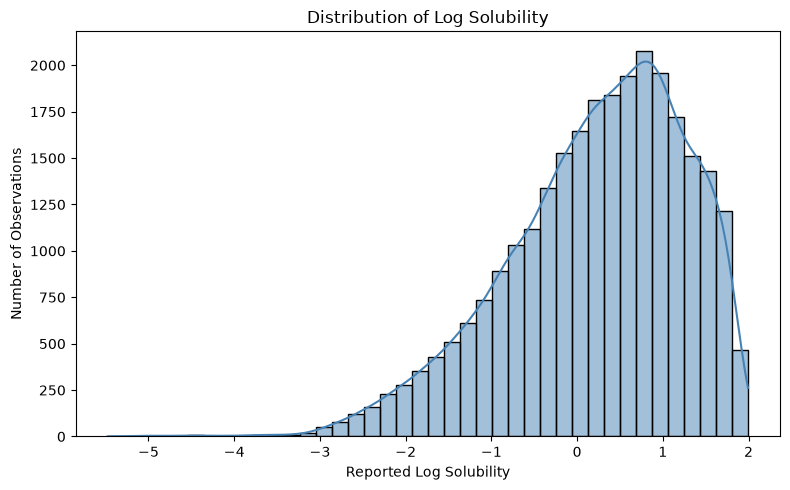

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="value",
    bins=40,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Log Solubility")
plt.xlabel("Reported Log Solubility")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "log_solubility_distribution.png", dpi=300)
plt.show()

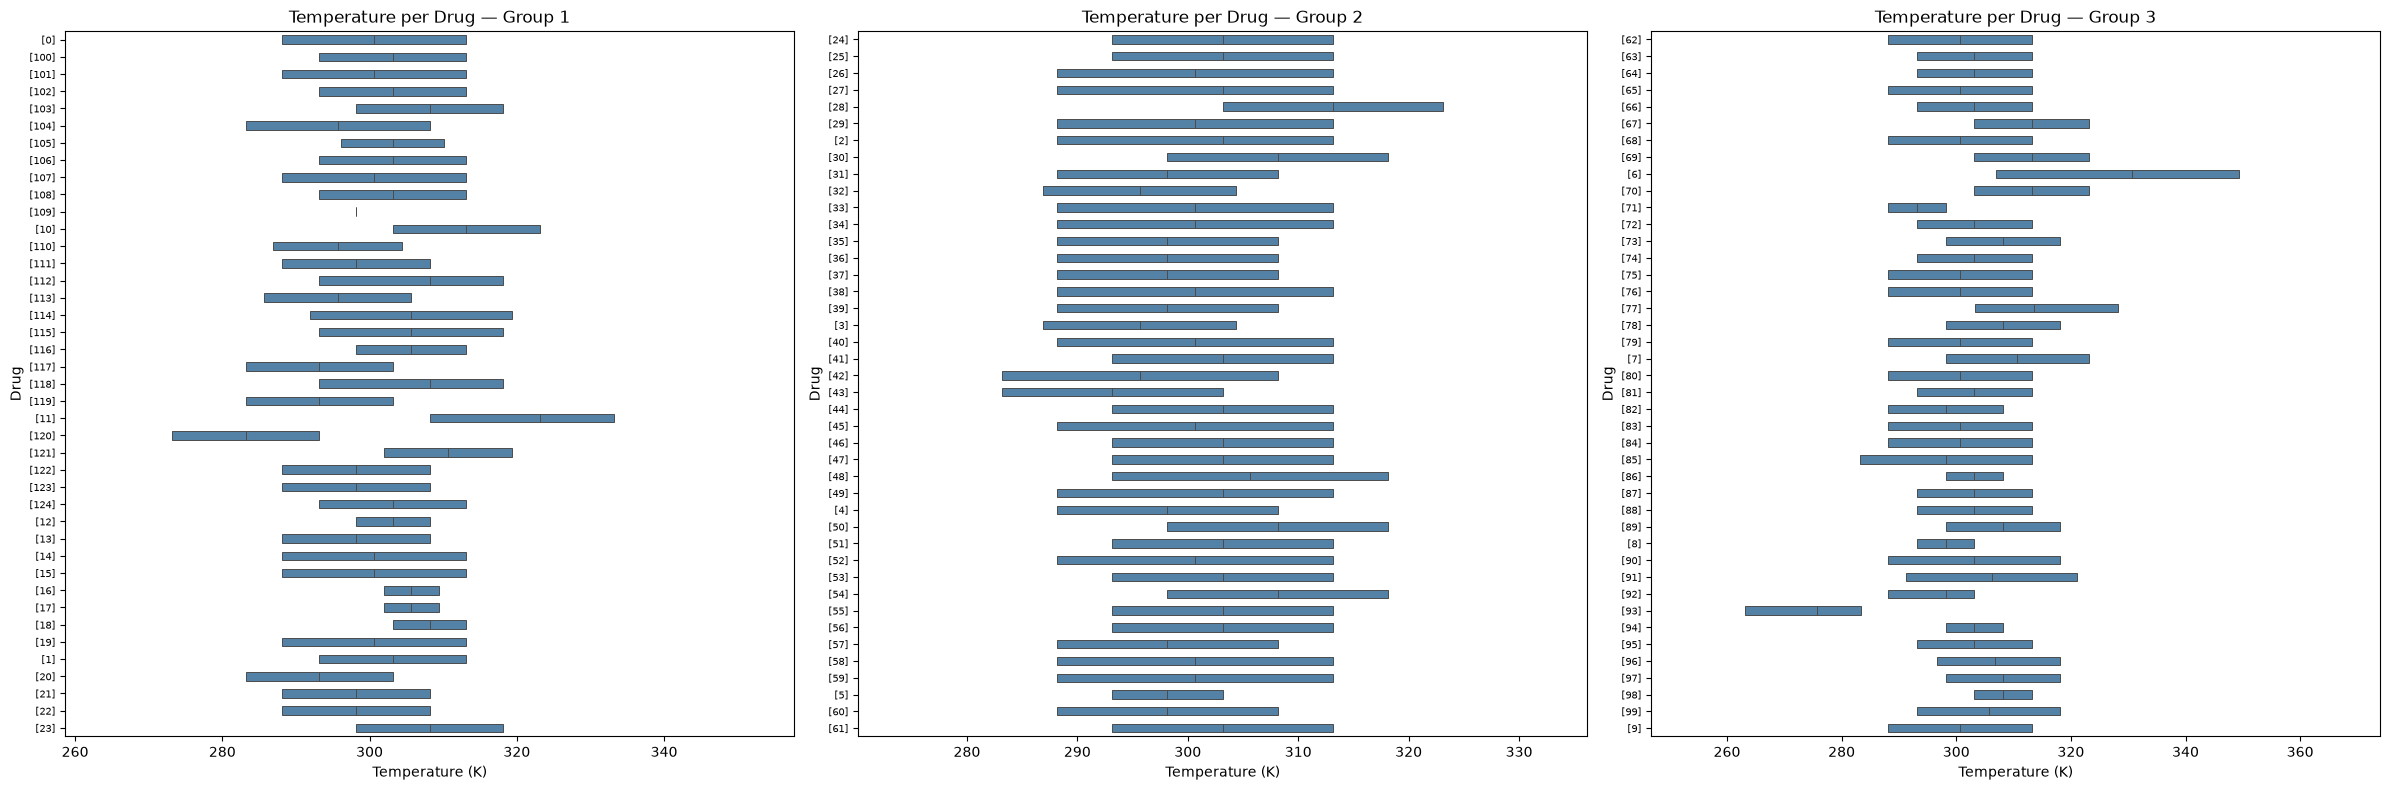

In [9]:
drug_col = "cmp_ids_drug"
drugs = sorted(df[drug_col].dropna().unique())

plt.figure(figsize=(24, 8))

# Split the drugs into three groups
for i in range(3):
    start = i * len(drugs) // 3
    end = (i + 1) * len(drugs) // 3
    group = drugs[start:end]

    plot_data = df[df[drug_col].isin(group)]

    plt.subplot(1, 3, i + 1)

    sns.boxplot(
        data=plot_data,
        x="Temperature, K",
        y=drug_col,
        order=group,
        orient="h",
        color="steelblue",
        width=0.5,
        linewidth=0.7,
        fliersize=2,
        whiskerprops={"visible": False},
        capprops={"visible": False}
    )

    plt.title("Temperature per Drug — Group " + str(i + 1))
    plt.xlabel("Temperature (K)")
    plt.ylabel("Drug")
    plt.yticks(fontsize=7)

    
plt.tight_layout()
plt.savefig(RESULTS_DIR / "temperature_distribution.png", dpi=300)
plt.show()

In [10]:
# Convert the text to lists and compare their lengths
mismatch = (
    df["cmp_ids_solvent"].apply(ast.literal_eval).apply(len)
    != df["cmp_mole_fractions_solvent"].apply(ast.literal_eval).apply(len)
)

# Count mismatched rows and show the first 10
print("Rows with different list lengths:", mismatch.sum())
print(df.loc[mismatch, ["cmp_ids_solvent", "cmp_mole_fractions_solvent"]].head(10))

Rows with different list lengths: 453
     cmp_ids_solvent cmp_mole_fractions_solvent
3815  [127.0, 129.0]                      [1.0]
3816  [127.0, 129.0]                      [1.0]
3817  [127.0, 129.0]                      [1.0]
3818  [127.0, 129.0]                      [1.0]
3819  [127.0, 129.0]                      [1.0]
3820  [127.0, 129.0]                      [1.0]
3821  [127.0, 129.0]                      [1.0]
3822  [127.0, 129.0]                      [1.0]
3823  [127.0, 129.0]                      [1.0]
3824  [127.0, 129.0]                      [1.0]


In [11]:
# Load the raw data and compare row counts
raw = pd.read_csv(RAW_DIR / "DrugSolubilityData.csv")
print("Raw rows:", len(raw))
print("Processed rows:", len(df))

# Check that measurements and temperatures match in the same row order
assert len(raw) == len(df), "Row counts differ"
assert (raw["LogS"].values == df["value"].values).all(), "Measurement values differ"
assert (raw["Temperature, K"].values == df["Temperature, K"].values).all(), "Temperatures differ"

print("Initial alignment checks passed")

Raw rows: 27166
Processed rows: 27166
Initial alignment checks passed


In [12]:
# Compare solvent information in the same processed and raw row
print("Processed record:")
print(df.iloc[3815][["cmp_ids_solvent", "cmp_mole_fractions_solvent"]])

print("\nRaw record:")
print(raw.iloc[3815][["SMILES_1", "comp_1", "SMILES_2", "comp_2"]])

Processed record:
cmp_ids_solvent               [127.0, 129.0]
cmp_mole_fractions_solvent             [1.0]
Name: 3815, dtype: object

Raw record:
SMILES_1       OC
comp_1      100.0
SMILES_2        O
comp_2        0.0
Name: 3815, dtype: object


In [13]:
# Load compound IDs and SMILES
compounds = pd.read_csv(PROCESSED_DIR / "compounds.csv")
print(compounds[["compound_id", "smiles"]].head())

# Find methanol (OC) and water (O)
print(compounds.loc[
    compounds["smiles"].str.strip().isin(["OC", "O"]),
    ["compound_id", "smiles"]
])

# Count solvent compositions in the mismatched rows
print("\nAffected compositions:")
print(raw.loc[mismatch, ["comp_1", "comp_2"]].value_counts(dropna=False))

   compound_id                                             smiles
0            0                                         Cl.N=C(N)N
1            1                           Cl.O=CC(N)C(O)C(O)C(O)CO
2            2                                   ClC=1N=C(N)C=NC1
3            3     O=N(=O)[O-].OCCC=1SC=[N+](C1C)CC2=CN=C(N=C2N)C
4            4  O=C1NC2=CC(OCCCCN3CCN(C=4C=CC=C(Cl)C4Cl)CC3)=C...
     compound_id smiles
127          127     OC
129          129      O

Affected compositions:
comp_1  comp_2
100.0   0.0       433
0.0     100.0      20
Name: count, dtype: int64


In [14]:
# Check whether a row contains one positive solvent fraction
# and whether all fractions add up to 1
def is_pure_solvent(fractions):
    positive_count = 0

    for fraction in fractions:
        if fraction > 0:
            positive_count += 1

    total_fraction = sum(fractions)

    return positive_count == 1 and np.isclose(
        total_fraction, 1, rtol=0, atol=1e-6
    )


# Convert the stored fraction lists and identify pure-solvent rows
solvent_fractions = df["cmp_mole_fractions_solvent"].apply(ast.literal_eval)
pure_solvent_mask = solvent_fractions.apply(is_pure_solvent)


# Identify missing or blank solvent identifiers
def is_missing_identifier(column):
    return column.fillna("").str.strip() == ""


missing_first = is_missing_identifier(raw["SMILES_1"])
missing_second = is_missing_identifier(raw["SMILES_2"])

# Select pure-solvent rows with at least one missing identifier
matching_mask = pure_solvent_mask & (missing_first | missing_second)

columns_to_show = [
    "SMILES_0", "SMILES_1", "comp_1", "SMILES_2", "comp_2",
    "Temperature, K", "LogS"
]

raw_pure_missing_solvent = raw.loc[matching_mask, columns_to_show].copy()

# Add flags and processed values for comparison
raw_pure_missing_solvent["missing_SMILES_1"] = missing_first
raw_pure_missing_solvent["missing_SMILES_2"] = missing_second
raw_pure_missing_solvent["processed_solvent_ids"] = df["cmp_ids_solvent"]
raw_pure_missing_solvent["processed_solvent_fractions"] = df["cmp_mole_fractions_solvent"]
raw_pure_missing_solvent.index.name = "original_row_index"

# Count each type of missing identifier
missing_only_first = pure_solvent_mask & missing_first & ~missing_second
missing_only_second = pure_solvent_mask & ~missing_first & missing_second
missing_both = pure_solvent_mask & missing_first & missing_second

# Display counts and matching rows
print("Total pure-solvent rows:", pure_solvent_mask.sum())
print("Missing only SMILES_1:", missing_only_first.sum())
print("Missing only SMILES_2:", missing_only_second.sum())
print("Missing both identifiers:", missing_both.sum())
print("Total matching rows:", len(raw_pure_missing_solvent))

display(raw_pure_missing_solvent)

Total pure-solvent rows: 2943
Missing only SMILES_1: 1041
Missing only SMILES_2: 1449
Missing both identifiers: 0
Total matching rows: 2490


,SMILES_0,SMILES_1,comp_1,SMILES_2,comp_2,"Temperature, K",LogS,missing_SMILES_1,missing_SMILES_2,processed_solvent_ids,processed_solvent_fractions
original_row_index,,,,,,,,,,,
15318,Cl.N1=C(NCC1)CC2=CC=CC=3C=CC=CC32,OC,100.0,NaN,0.0,278.15,0.8951,False,True,[127.0],[1.0]
15319,Cl.N1=C(NCC1)CC2=CC=CC=3C=CC=CC32,OC,100.0,NaN,0.0,283.15,0.9843,False,True,[127.0],[1.0]
15320,Cl.N1=C(NCC1)CC2=CC=CC=3C=CC=CC32,OC,100.0,NaN,0.0,288.15,1.0553,False,True,[127.0],[1.0]
15321,Cl.N1=C(NCC1)CC2=CC=CC=3C=CC=CC32,OC,100.0,NaN,0.0,293.15,1.1281,False,True,[127.0],[1.0]
15322,Cl.N1=C(NCC1)CC2=CC=CC=3C=CC=CC32,OC,100.0,NaN,0.0,298.15,1.2057,False,True,[127.0],[1.0]
...,...,...,...,...,...,...,...,...,...,...,...
27161,O=C(OC)NC1=NC=2C=CC=CC2N1,OCCC,100.0,NaN,0.0,298.15,-2.2307,False,True,[131.0],[1.0]
27162,O=C(OC)NC1=NC=2C=CC=CC2N1,OCCC,100.0,NaN,0.0,303.15,-2.0617,False,True,[131.0],[1.0]
27163,O=C(OC)NC1=NC=2C=CC=CC2N1,OCCC,100.0,NaN,0.0,308.15,-1.8914,False,True,[131.0],[1.0]


In [15]:
# Map solvent SMILES to compound IDs
solvent_smiles = compounds["smiles"].str.strip()
solvent_ids = compounds["compound_id"]
smiles_to_id = dict(zip(solvent_smiles, solvent_ids))

# Read the existing solvent lists
id_lists = df["cmp_ids_solvent"].apply(ast.literal_eval)
fraction_lists = df["cmp_mole_fractions_solvent"].apply(ast.literal_eval)

# Count the entries in each list
id_counts = id_lists.apply(len)
fraction_counts = fraction_lists.apply(len)

# Identify rows to repair
mismatch = id_counts != fraction_counts
single_solvent_mask = (id_counts == 1) & (fraction_counts == 1)
repair_mask = mismatch | single_solvent_mask

# Create a copy to store the repaired data
repaired = df.copy()

for idx in df.index[repair_mask]:
    ids = []
    fractions = []

    # Read both solvent slots in their original order
    for position in [1, 2]:
        smiles_column = "SMILES_" + str(position)
        fraction_column = "comp_" + str(position)

        raw_smiles = raw.loc[idx, smiles_column]

        if pd.isna(raw_smiles) or raw_smiles.strip() == "":
            ids.append("N/A")
            fractions.append(0.0)

        else:
            clean_smiles = raw_smiles.strip()
            compound_id = int(smiles_to_id[clean_smiles])
            fraction = float(raw.loc[idx, fraction_column]) / 100

            ids.append(compound_id)
            fractions.append(fraction)

    # Save the rebuilt lists
    repaired.loc[idx, "cmp_ids_solvent"] = str(ids)
    repaired.loc[idx, "cmp_mole_fractions_solvent"] = str(fractions)

# Display the repair counts
print("Length mismatches repaired:", mismatch.sum())
print("Single-solvent rows expanded:", single_solvent_mask.sum())
print("Total rows updated:", repair_mask.sum())
print("Rows retained:", len(repaired))

Length mismatches repaired: 453
Single-solvent rows expanded: 2490
Total rows updated: 2943
Rows retained: 27166


In [16]:
# Get active components, ignoring zero-fraction slots
def active_composition(ids_text, fractions_text):
    ids = ast.literal_eval(ids_text)
    fractions = ast.literal_eval(fractions_text)

    active_components = []

    for cid, fraction in zip(ids, fractions):
        if fraction > 0:
            active_components.append((int(cid), float(fraction)))

    active_components.sort()

    return tuple(active_components)


# Keep the other fields for duplicate comparisons
duplicate_keys = repaired.drop(columns=[
    "cmp_ids_drug",
    "cmp_ids_solvent",
    "cmp_mole_fractions_solvent"
]).copy()

# Add active compositions for drugs and solvents
for kind in ["drug", "solvent"]:
    id_column = "cmp_ids_" + kind
    fraction_column = "cmp_mole_fractions_" + kind
    composition_column = "active_" + kind + "_composition"

    compositions = []

    for ids, fractions in zip(
        repaired[id_column],
        repaired[fraction_column]
    ):
        composition = active_composition(ids, fractions)
        compositions.append(composition)

    duplicate_keys[composition_column] = compositions

# Flag repeated rows while keeping the first occurrence
duplicate_mask = duplicate_keys.duplicated(keep="first")

# Identify all rows belonging to duplicate groups
all_duplicates_mask = duplicate_keys.duplicated(keep=False)

print("Exact text-based duplicates:", repaired.duplicated().sum())
print("Duplicate rows to remove:", duplicate_mask.sum())

display(repaired.loc[all_duplicates_mask])

Exact text-based duplicates: 0
Duplicate rows to remove: 9


,value,"Temperature, K",property,unit,cmp_ids_solvent,cmp_mole_fractions_solvent,cmp_ids_drug,cmp_mole_fractions_drug
7905,0.8258,278.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7906,0.8851,283.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7907,0.9437,288.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7908,1.0033,293.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7909,1.0609,298.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7910,1.1096,303.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7911,1.1606,308.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7912,1.2084,313.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7913,1.2571,318.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7995,0.8258,278.15,Log solubility,g/L,"[145, 140]","[1.0, 0.0]",[36],[1.0]


In [17]:
# Remove duplicates, keeping the first occurrence
removed_duplicates = repaired.loc[duplicate_mask].copy()
cleaned = repaired.loc[~duplicate_mask].copy()

# Report row counts before and after removal
print("Rows before duplicate removal:", len(repaired))
print("Duplicate rows removed:", len(removed_duplicates))
print("Rows after duplicate removal:", len(cleaned))

Rows before duplicate removal: 27166
Duplicate rows removed: 9
Rows after duplicate removal: 27157


In [18]:
# Prepare all observations for outlier analysis
review = cleaned.copy()

# Label every drug consistently
review["drug_id"] = (
    review["cmp_ids_drug"]
    .apply(ast.literal_eval)
    .apply(lambda ids: int(ids[0]))
)
review["drug"] = review["drug_id"].apply(lambda cid: f"Drug {cid}")

# Classify observations by the number of positive solvent fractions
active_solvent_counts = (
    review["cmp_mole_fractions_solvent"]
    .apply(ast.literal_eval)
    .apply(lambda fractions: sum(fraction > 0 for fraction in fractions))
)

assert active_solvent_counts.isin([1, 2]).all(), (
    "Unexpected number of active solvents"
)

review["solvent_type"] = np.where(
    active_solvent_counts.eq(1), "pure", "binary"
)

# Group recorded solvent IDs, retaining zero-fraction solvents
def get_solvent_pair(text):
    return tuple(sorted(
        int(cid)
        for cid in ast.literal_eval(text)
        if cid != "N/A"
    ))

review["solvent_pair"] = review["cmp_ids_solvent"].apply(get_solvent_pair)

In [19]:
# Flag observations within each drug–solvent-pair group
iqr_review = review.copy()

flag_columns = ["LogS_iqr_flag", "Temperature_iqr_flag"]
iqr_review[flag_columns] = False

for _, group in iqr_review.groupby(["drug", "solvent_pair"]):
    for column, flag_column in [
        ("value", "LogS_iqr_flag"),
        ("Temperature, K", "Temperature_iqr_flag")
    ]:
        values = group[column]
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        flags = (
            (values < q1 - 1.5 * iqr)
            | (values > q3 + 1.5 * iqr)
        )

        iqr_review.loc[group.index, flag_column] = flags

# Identify observations flagged for either variable
flagged_mask = iqr_review[flag_columns].any(axis=1)

print("Total observations:", len(iqr_review))
print("LogS flags:", int(iqr_review["LogS_iqr_flag"].sum()))
print("Temperature flags:", int(iqr_review["Temperature_iqr_flag"].sum()))
print("Unique flagged observations:", int(flagged_mask.sum()))

Total observations: 27157
LogS flags: 311
Temperature flags: 0
Unique flagged observations: 311


In [20]:
# Retain flagged observations by default
outlier_policy_report = iqr_review.loc[flagged_mask].copy()
outlier_policy_report["decision"] = "retain"
outlier_policy_report[["reason", "evidence"]] = ""

# Enter confirmed errors using their original row indices
confirmed_outlier_errors = {
    # ROW_INDEX: {"reason": "Confirmed error", "evidence": "Supporting source"}
}

for idx, details in confirmed_outlier_errors.items():
    assert idx in outlier_policy_report.index, f"Row {idx} is not flagged"
    outlier_policy_report.loc[idx, ["decision", "reason", "evidence"]] = [
        "remove", details["reason"], details["evidence"]
    ]

# Remove only confirmed errors
remove_indices = outlier_policy_report.index[
    outlier_policy_report["decision"] == "remove"
]
final_data = cleaned.drop(index=remove_indices)

final_data.to_csv(
    RESULTS_DIR / "cleaned_drug_solubility.csv",
    index=False
)

outlier_policy_report.to_csv(
    RESULTS_DIR / "outlier_policy_report.csv",
    index_label="original_row_index"
)

print("Rows before outlier decisions:", len(cleaned))
print("IQR-flagged observations retained:", len(outlier_policy_report) - len(remove_indices))
print("Confirmed erroneous observations removed:", len(remove_indices))
print("Final dataset rows:", len(final_data))

Rows before outlier decisions: 27157
IQR-flagged observations retained: 311
Confirmed erroneous observations removed: 0
Final dataset rows: 27157


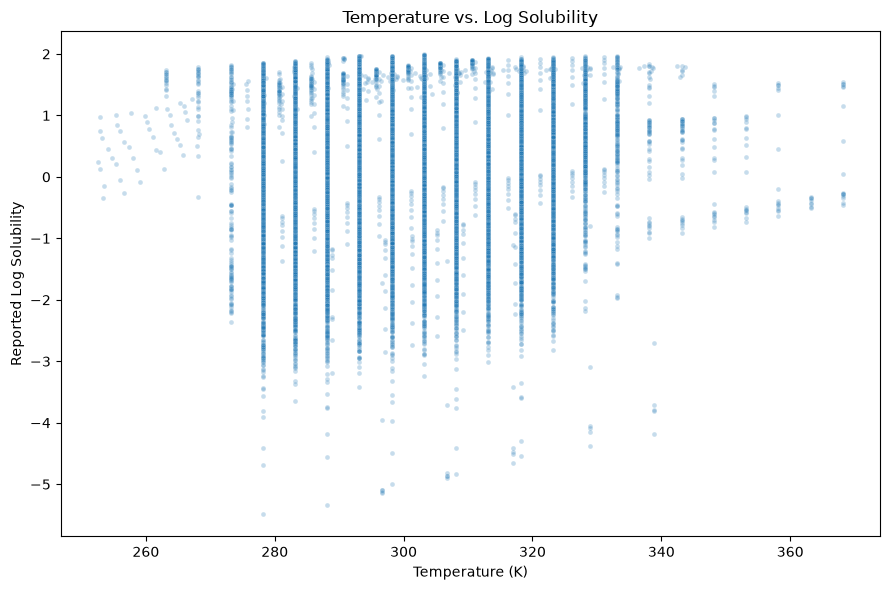

In [21]:
#Plotting correltion between temperature and log solubility
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=final_data,
    x="Temperature, K",
    y="value",
    alpha=0.25,
    s=12
)

plt.title("Temperature vs. Log Solubility")
plt.xlabel("Temperature (K)")
plt.ylabel("Reported Log Solubility")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "temperature_vs_log_solubility.png", dpi=300)
plt.show()


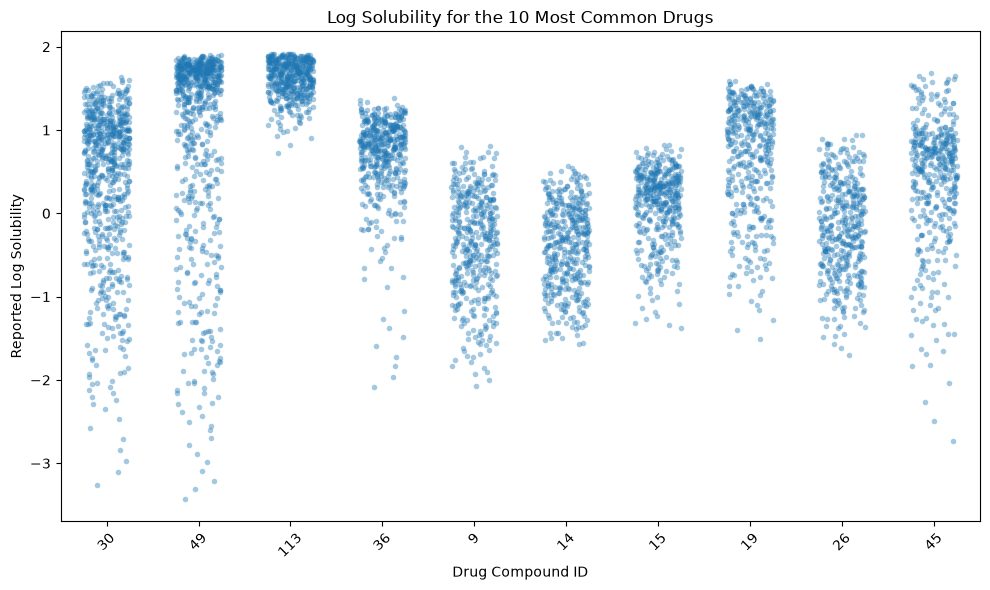

In [22]:
# Extract the single drug ID from each observation
plot_df = final_data.copy()
plot_df["drug_id"] = (
    plot_df["cmp_ids_drug"].apply(ast.literal_eval)
    .apply(lambda ids: str(int(ids[0])))
)

# Select the 10 most common drugs
top_drugs = plot_df["drug_id"].value_counts().head(10).index
plot_df = plot_df.loc[plot_df["drug_id"].isin(top_drugs)]

# Compare their log solubility values
plt.figure(figsize=(10, 6))
sns.stripplot(
    data=plot_df, x="drug_id", y="value", order=top_drugs,
    jitter=0.25, alpha=0.4, size=4
)
plt.title("Log Solubility for the 10 Most Common Drugs")
plt.xlabel("Drug Compound ID")
plt.ylabel("Reported Log Solubility")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "top10_drugs_log_solubility.png", dpi=300)
plt.show()

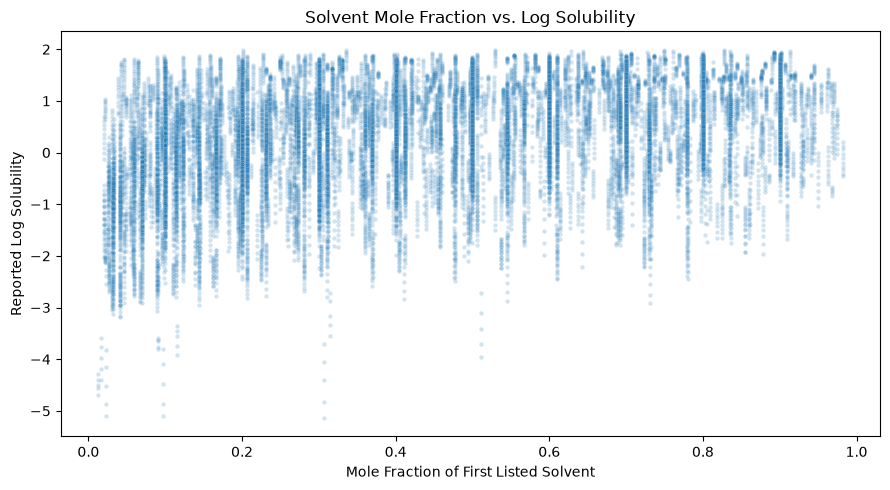

In [23]:
#Correlation between solvent mole fraction and log solubility for binary mixtures

# Select cleaned observations with two positive solvent fractions
solvent_fractions = final_data[
    "cmp_mole_fractions_solvent"
].apply(ast.literal_eval)

binary_mask = solvent_fractions.apply(
    lambda fractions: (np.array(fractions) > 1e-10).sum() == 2
)

binary_df = final_data.loc[binary_mask].copy()

binary_df["solvent_1_fraction"] = (
    solvent_fractions.loc[binary_mask]
    .apply(lambda fractions: fractions[0])
)

# Plot log solubility against the first listed solvent's mole fraction
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=binary_df, x="solvent_1_fraction", y="value", alpha=0.2, s=10
)
plt.title("Solvent Mole Fraction vs. Log Solubility")
plt.xlabel("Mole Fraction of First Listed Solvent")
plt.ylabel("Reported Log Solubility")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "solvent_fraction_vs_log_solubility.png", dpi=300)
plt.show()

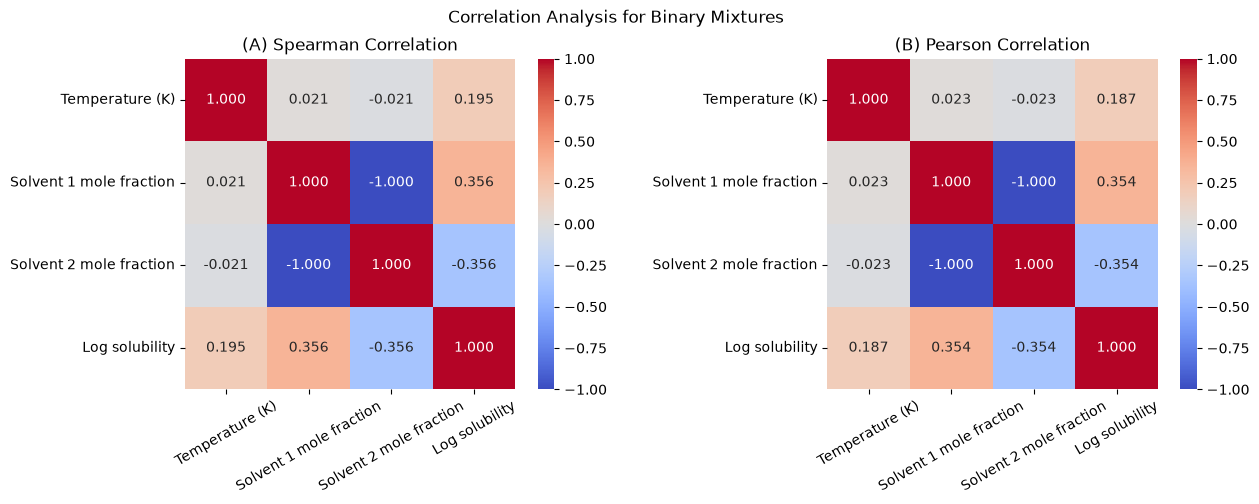

In [24]:
# Extract the second listed solvent's mole fraction
binary_df["solvent_2_fraction"] = (
    binary_df["cmp_mole_fractions_solvent"]
    .apply(ast.literal_eval)
    .apply(lambda fractions: fractions[1])
)

# Calculate correlations using all four variables
correlation_data = binary_df[
    ["Temperature, K", "solvent_1_fraction", "solvent_2_fraction", "value"]
].rename(columns={
    "solvent_1_fraction": "Solvent 1 mole fraction",
    "solvent_2_fraction": "Solvent 2 mole fraction",
    "value": "Log solubility",
    "Temperature, K": "Temperature (K)"
})

spearman_corr = correlation_data.corr(method="spearman")
correlation = correlation_data.corr()

# Compare Spearman and Pearson correlations
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, matrix, title in zip(
    axes, [spearman_corr, correlation], ["(A) Spearman Correlation", "(B) Pearson Correlation"]
):
    sns.heatmap(
        matrix, ax=ax, annot=True, fmt=".3f", cmap="coolwarm",
        vmin=-1, vmax=1, center=0, square=True
    )
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)

fig.suptitle("Correlation Analysis for Binary Mixtures")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "binary_mixture_correlations.png", dpi=300)
plt.show()

In [25]:
#Define the global variables
RANDOM_SEED = 1
np.random.seed(RANDOM_SEED)
LogSolubility = "value"
FeatureColumns = [
    "Temperature, K",
    "cmp_mole_fractions_solvent",
    "cmp_ids_solvent",
    "cmp_ids_drug",
]

# Use the final cleaned dataset
model_data = final_data.copy()

# Train/test stratification split of the log solubility values
LogSolubility_Binary = "value_binary"
Cutoff = model_data[LogSolubility].quantile(0.9)

model_data[LogSolubility_Binary] = (
    model_data[LogSolubility] > Cutoff
).astype(int)

train_df, test_df = train_test_split(
    model_data,
    test_size=0.2,
    train_size=0.8,
    stratify=model_data[LogSolubility_Binary],
    random_state=RANDOM_SEED
)

# Check the split
print("Cleaned observations:", len(model_data))
print("Training observations:", len(train_df))
print("Test observations:", len(test_df))

train_df.head(5)


Cleaned observations: 27157
Training observations: 21725
Test observations: 5432


,value,"Temperature, K",property,unit,cmp_ids_solvent,cmp_mole_fractions_solvent,cmp_ids_drug,cmp_mole_fractions_drug,value_binary
12353,1.3673,323.15,Log solubility,g/L,"[144.0, 130.0]","[0.4, 0.6]",[54],[1.0],0
16340,1.1238,318.15,Log solubility,g/L,"[125.0, 130.0]","[0.295599, 0.704401]",[76],[1.0],0
1910,-0.4298,278.15,Log solubility,g/L,"[140.0, 129.0]","[0.166615, 0.8333849999999999]",[9],[1.0],0
398,0.6872,323.15,Log solubility,g/L,"[131.0, 129.0]","[0.729656, 0.27034400000000003]",[2],[1.0],0
16091,1.2003,288.15,Log solubility,g/L,"[142.0, 145.0]","[0.34370399999999995, 0.656296]",[75],[1.0],0


In [26]:
test_df.head(5)

,value,"Temperature, K",property,unit,cmp_ids_solvent,cmp_mole_fractions_solvent,cmp_ids_drug,cmp_mole_fractions_drug,value_binary
6783,1.5685,323.15,Log solubility,g/L,"[138, 129]","[1.0, 0.0]",[30],[1.0],1
11500,0.0902,298.15,Log solubility,g/L,"[127.0, 144.0]","[0.657715, 0.34228499999999995]",[50],[1.0],0
9856,0.0850,303.15,Log solubility,g/L,"[127.0, 129.0]","[0.194208, 0.805792]",[45],[1.0],0
7994,1.2509,318.15,Log solubility,g/L,"[145.0, 140.0]","[0.859916, 0.140084]",[36],[1.0],0
5355,0.2781,288.15,Log solubility,g/L,"[125.0, 129.0]","[0.19778099999999998, 0.802219]",[26],[1.0],0


In [27]:
def parse_id_list(value):
    if isinstance(value, str):
        value = ast.literal_eval(value)
    if isinstance(value, (list, tuple)):
        return list(value)
    if pd.isna(value):
        return []
    return [value]

def id_category(value):
    try:
        number = float(value)
        return str(int(number)) if number.is_integer() else str(number)
    except (TypeError, ValueError):
        return str(value)

descriptor_functions = {
    "MolWt": Descriptors.MolWt,
    "MolLogP": Descriptors.MolLogP,
    "TPSA": Descriptors.TPSA,
    "NumHDonors": Descriptors.NumHDonors,
    "NumHAcceptors": Descriptors.NumHAcceptors,
    "NumRotatableBonds": Descriptors.NumRotatableBonds,
    "RingCount": Descriptors.RingCount,
    "HeavyAtomCount": Descriptors.HeavyAtomCount,
}

compound_table = pd.read_csv(PROCESSED_DIR / "compounds.csv")
if not {"compound_id", "smiles"}.issubset(compound_table.columns):
    raise ValueError("compounds.csv must contain compound_id and smiles columns.")
compound_table = compound_table[["compound_id", "smiles"]].copy()
compound_table["compound_id"] = compound_table["compound_id"].map(id_category)
if compound_table["compound_id"].duplicated().any():
    raise ValueError("compounds.csv contains duplicate compound IDs.")
smiles_by_id = compound_table.set_index("compound_id")["smiles"].to_dict()
descriptor_cache = {}

def molecular_descriptors(compound_id):
    if compound_id is None or pd.isna(compound_id):
        return {name: 0.0 for name in descriptor_functions}

    compound_id = id_category(compound_id)
    if compound_id in {"N/A", "__missing__"}:
        return {name: 0.0 for name in descriptor_functions}
    if compound_id not in smiles_by_id:
        raise KeyError(f"Compound ID {compound_id} is missing from compounds.csv.")

    if compound_id not in descriptor_cache:
        smiles = smiles_by_id[compound_id]
        molecule = Chem.MolFromSmiles(smiles)
        if molecule is None:
            raise ValueError(f"Invalid SMILES for compound ID {compound_id}: {smiles}")
        descriptor_cache[compound_id] = {
            name: float(function(molecule))
            for name, function in descriptor_functions.items()
        }

    return descriptor_cache[compound_id]

def fraction_at(values, position):
    if len(values) <= position or values[position] is None:
        return 0.0
    fraction = float(values[position])
    return fraction if np.isfinite(fraction) else 0.0

def make_features(frame):
    X = frame[["Temperature, K"]].copy()
    solvent_ids = frame["cmp_ids_solvent"].apply(parse_id_list)
    solvent_fractions = frame["cmp_mole_fractions_solvent"].apply(parse_id_list)
    drug_ids = frame["cmp_ids_drug"].apply(parse_id_list)

    for position in range(2):
        component_ids = solvent_ids.apply(
            lambda ids: ids[position] if len(ids) > position else None
        )
        X[f"solvent_{position + 1}_fraction"] = solvent_fractions.apply(
            lambda values: fraction_at(values, position)
        )
        for name in descriptor_functions:
            X[f"solvent_{position + 1}_{name}"] = component_ids.apply(
                lambda compound_id: molecular_descriptors(compound_id)[name]
            )

    drug_id = drug_ids.apply(lambda ids: ids[0] if ids else None)
    for name in descriptor_functions:
        X[f"drug_{name}"] = drug_id.apply(
            lambda compound_id: molecular_descriptors(compound_id)[name]
        )

    return X

X_train = make_features(train_df)
X_test = make_features(test_df)

scaled_columns = [
    "Temperature, K",
    "solvent_1_fraction",
    "solvent_2_fraction",
]
preprocessor = ColumnTransformer(
    [("scale_temperature_and_fractions", StandardScaler(), scaled_columns)],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

_feature_check = clone(preprocessor)
_X_train_check = _feature_check.fit_transform(X_train)
_X_test_check = _feature_check.transform(X_test)
assert np.isfinite(_X_train_check).all() and np.isfinite(_X_test_check).all()
assert _X_train_check.shape[1] == X_train.shape[1] == X_test.shape[1]
print(
    f"Feature check passed: {X_train.shape[1]} numeric features; "
    "only temperature and mole fractions are scaled."
)

LinearRegression_Model = make_pipeline(preprocessor, LinearRegression())

Feature check passed: 27 numeric features; only temperature and mole fractions are scaled.


In [28]:
#Define a function that returns a dictionary with calculated model performance metrics
def model_performance_metrics(model, X, y_true):
    #predict the model using this estimator object
    y_predict = model.predict(X)
    mean_abs_error = mean_absolute_error(y_true, y_predict)
    root_mean_squared_error = np.sqrt(mean_squared_error(y_true, y_predict))

    metrics_dictionary = {
        'mae': mean_abs_error,
        'rmse': root_mean_squared_error,
    }
    return metrics_dictionary

#Train the model using the train portion of the dataset
LinearRegression_Model.fit(X_train, train_df[LogSolubility])

#Results of training the model on the training dataset
linear_regression_results_train = model_performance_metrics(LinearRegression_Model, X_train, train_df[LogSolubility])

#Results of testing the model on the test dataset
linear_regression_results_test = model_performance_metrics(LinearRegression_Model, X_test, test_df[LogSolubility])

print("Linear Regression Model Performance Metrics (Train):", linear_regression_results_train)
print("Linear Regression Model Performance Metrics (Test):", linear_regression_results_test)



Linear Regression Model Performance Metrics (Train): {'mae': 0.6664986626826365, 'rmse': np.float64(0.8493898785957017)}
Linear Regression Model Performance Metrics (Test): {'mae': 0.6725870553045884, 'rmse': np.float64(0.8607635991221292)}


In [29]:
# Ridge Hyperparameter Optimization using GridSearchCV with cross validation 
Ridge_Model = make_pipeline(
    preprocessor,
    StandardScaler(with_mean=False),
    Ridge(alpha=10)
)

ridge_param_grid = {
    "ridge__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
}

ridge_grid = GridSearchCV(
    estimator=Ridge_Model,
    param_grid=ridge_param_grid,
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=-1
)

ridge_grid.fit(X_train, train_df[LogSolubility])

print("Best Ridge alpha:", ridge_grid.best_params_["ridge__alpha"])
print("Best Ridge CV RMSE:", (-ridge_grid.best_score_) ** 0.5)

Best Ridge alpha: 1.0
Best Ridge CV RMSE: 0.8501097446076696


In [30]:
# Evaluate the best Ridge model
Ridge_Model = ridge_grid.best_estimator_

ridge_results_train = model_performance_metrics(
    Ridge_Model, X_train, train_df[LogSolubility]
)

ridge_results_test = model_performance_metrics(
    Ridge_Model, X_test, test_df[LogSolubility]
)

print("Tuned Ridge Train:", ridge_results_train)
print("Tuned Ridge Test:", ridge_results_test)

Tuned Ridge Train: {'mae': 0.6665028141809392, 'rmse': np.float64(0.8493899141426008)}
Tuned Ridge Test: {'mae': 0.6725965808108385, 'rmse': np.float64(0.8607673453693208)}


In [31]:
# LASSO Hyperparameter Optimization using GridSearchCV with cross validation 
lasso_param_grid = {
    "lasso__alpha": [0.00001, 0.0001, 0.001, 0.01, 0.1]
}

Lasso_Model = make_pipeline(
    preprocessor,
    StandardScaler(with_mean=False),
    Lasso(alpha=0.0001, max_iter=50000)
)

lasso_grid = GridSearchCV(
    estimator=Lasso_Model,
    param_grid=lasso_param_grid,
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=-1
)

lasso_grid.fit(X_train, train_df[LogSolubility])

print("Best LASSO alpha:", lasso_grid.best_params_["lasso__alpha"])
print("Best LASSO CV RMSE:", (-lasso_grid.best_score_) ** 0.5)

# Update the model and metrics using the tuned LASSO
Lasso_Model = lasso_grid.best_estimator_

lasso_results_train = model_performance_metrics(
    Lasso_Model, X_train, train_df[LogSolubility]
)
lasso_results_test = model_performance_metrics(
    Lasso_Model, X_test, test_df[LogSolubility]
)

Best LASSO alpha: 1e-05
Best LASSO CV RMSE: 0.8501099514132745


In [32]:
# Model Performance Comparison with and without Regulatization of LASSO and Ridge Regression
comparison_df = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression", "LASSO Regression"],
    "Test MAE": [
        linear_regression_results_test["mae"],
        ridge_results_test["mae"],
        lasso_results_test["mae"]
    ],
    "Test RMSE": [
        linear_regression_results_test["rmse"],
        ridge_results_test["rmse"],
        lasso_results_test["rmse"]
    ]
})

display(comparison_df.round(5))

,Model,Test MAE,Test RMSE
0,Linear Regression,0.67259,0.86076
1,Ridge Regression,0.67260,0.86077
2,LASSO Regression,0.67260,0.86077


In [33]:
# Set the file location for saved results
xgb_results_file = RESULTS_DIR / "xgboost_tuning_results_cleaned.joblib"

# Load saved results if the file exists
if xgb_results_file.exists():
    xgb_results = joblib.load(xgb_results_file)

# Tune the model if no saved results exist
else:
    # Create the preprocessing and model pipeline
    xgb_tuning_pipeline = make_pipeline(
        preprocessor,
        XGBRegressor(
            objective="reg:squarederror",
            random_state=42,
            n_jobs=1
        )
    )

    # Define the hyperparameters to test
    xgb_param_distributions = {
        "xgbregressor__n_estimators": [300, 600, 1000, 1500],
        "xgbregressor__learning_rate": [0.02, 0.05, 0.1],
        "xgbregressor__max_depth": [3, 6, 9],
        "xgbregressor__min_child_weight": [1, 5, 10],
        "xgbregressor__subsample": [0.7, 0.85, 1.0],
        "xgbregressor__colsample_bytree": [0.8, 0.9, 1.0],
        "xgbregressor__gamma": [0, 0.1, 1],
        "xgbregressor__reg_alpha": [0, 0.1, 1],
        "xgbregressor__reg_lambda": [1, 5, 10]
    }

    # Test 200 combinations using 5-fold cross-validation
    xgb_search = RandomizedSearchCV(
        estimator=xgb_tuning_pipeline,
        param_distributions=xgb_param_distributions,
        n_iter=200,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error"
        },
        refit="rmse",
        cv=5,
        n_jobs=-1,
        random_state=42
    )

    xgb_search.fit(X_train, train_df[LogSolubility])

    # Get the best model and its position in the search results
    XGBoost_Tuned_Model = xgb_search.best_estimator_
    xgb_best_index = xgb_search.best_index_

    # Remove the pipeline prefix from the hyperparameter names
    xgb_best_params = {}

    for name, value in xgb_search.best_params_.items():
        parameter_name = name.replace("xgbregressor__", "")
        xgb_best_params[parameter_name] = value

    # Get cross-validation errors for the selected model
    xgb_cv_mae = -xgb_search.cv_results_["mean_test_mae"][xgb_best_index]
    xgb_cv_rmse = -xgb_search.cv_results_["mean_test_rmse"][xgb_best_index]

    # Predict the training set
    xgb_predictions_train = XGBoost_Tuned_Model.predict(X_train)

    # Calculate training errors
    xgb_mae_train = mean_absolute_error(
        train_df[LogSolubility],
        xgb_predictions_train
    )

    xgb_rmse_train = np.sqrt(
        mean_squared_error(
            train_df[LogSolubility],
            xgb_predictions_train
        )
    )

    # Store the model and results
    xgb_results = {
        "model": XGBoost_Tuned_Model,
        "best_params": xgb_best_params,
        "cv_mae": xgb_cv_mae,
        "cv_rmse": xgb_cv_rmse,
        "train_mae": xgb_mae_train,
        "train_rmse": xgb_rmse_train
    }

    joblib.dump(xgb_results, xgb_results_file)

# Retrieve the saved or newly calculated results
XGBoost_Tuned_Model = xgb_results["model"]
xgb_best_params = xgb_results["best_params"]
xgb_cv_mae = xgb_results["cv_mae"]
xgb_cv_rmse = xgb_results["cv_rmse"]
xgb_mae_train = xgb_results["train_mae"]
xgb_rmse_train = xgb_results["train_rmse"]

# Display the results
print("Best Hyperparameters:", xgb_best_params)
print("Cross-Validated MAE:", round(xgb_cv_mae, 4))
print("Cross-Validated RMSE:", round(xgb_cv_rmse, 4))
print("XGBoost Training MAE:", round(xgb_mae_train, 4))
print("XGBoost Training RMSE:", round(xgb_rmse_train, 4))

Best Hyperparameters: {'subsample': 0.85, 'reg_lambda': 10, 'reg_alpha': 0.1, 'n_estimators': 1500, 'min_child_weight': 10, 'max_depth': 9, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 0.9}
Cross-Validated MAE: 0.0319
Cross-Validated RMSE: 0.0544
XGBoost Training MAE: 0.0117
XGBoost Training RMSE: 0.0196


In [34]:
# Load saved results or tune the model if no saved file exists
rf_results_file = RESULTS_DIR / "random_forest_tuning_results_cleaned.joblib"

if rf_results_file.exists():
    rf_results = joblib.load(rf_results_file)
else:
    rf_tuning_pipeline = make_pipeline(
        preprocessor, RandomForestRegressor(random_state=42)
    )

    # Define candidate hyperparameters
    rf_param_grid = {
        "randomforestregressor__n_estimators": [200, 300, 500, 800],
        "randomforestregressor__max_depth": [None, 10, 20, 30],
        "randomforestregressor__max_features": [0.4, 0.6, 0.8, 1.0],
        "randomforestregressor__min_samples_leaf": [1, 2, 5, 10]
    }

    # Evaluate 100 combinations using 10-fold CV and select the lowest RMSE
    rf_grid = RandomizedSearchCV(
        estimator=rf_tuning_pipeline,
        param_distributions=rf_param_grid,
        n_iter=100,
        scoring={
         "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error"
         },
        refit="rmse",
        cv=10,
        n_jobs=1,
        pre_dispatch=1,
        random_state=42,
        verbose=1
)
    
    rf_grid.fit(X_train, train_df[LogSolubility])

    RandomForest_Tuned_Model = rf_grid.best_estimator_
    rf_best_index = rf_grid.best_index_
    rf_tuned_predictions_train = RandomForest_Tuned_Model.predict(X_train)

    # Remove pipeline prefixes from the reported parameter names
    rf_best_params = {}
    for name, value in rf_grid.best_params_.items():
        rf_best_params[name.split("__")[1]] = value

    # Save the model and its CV and training metrics
    rf_results = {
        "model": RandomForest_Tuned_Model,
        "best_params": rf_best_params,
        "cv_mae": -rf_grid.cv_results_["mean_test_mae"][rf_best_index],
        "cv_rmse": -rf_grid.cv_results_["mean_test_rmse"][rf_best_index],
        "train_mae": mean_absolute_error(
            train_df[LogSolubility], rf_tuned_predictions_train
        ),
        "train_rmse": np.sqrt(mean_squared_error(
            train_df[LogSolubility], rf_tuned_predictions_train
        ))
    }
    joblib.dump(rf_results, rf_results_file)

# Retrieve results from either the saved file or the new tuning run
RandomForest_Tuned_Model = rf_results["model"]
rf_best_params = rf_results["best_params"]
rf_cv_mae = rf_results["cv_mae"]
rf_cv_rmse = rf_results["cv_rmse"]
rf_tuned_mae_train = rf_results["train_mae"]
rf_tuned_rmse_train = rf_results["train_rmse"]

print("Best Hyperparameters:", rf_best_params)
print(f"Cross-Validated MAE (mean across 10 folds): {rf_cv_mae:.4f}")
print(f"Cross-Validated RMSE (mean across 10 folds): {rf_cv_rmse:.4f}")
print(f"Random Forest Training MAE: {rf_tuned_mae_train:.4f}")
print(f"Random Forest Training RMSE: {rf_tuned_rmse_train:.4f}")

Best Hyperparameters: {'n_estimators': 800, 'min_samples_leaf': 1, 'max_features': 0.6, 'max_depth': None}
Cross-Validated MAE (mean across 10 folds): 0.0453
Cross-Validated RMSE (mean across 10 folds): 0.0727
Random Forest Training MAE: 0.0160
Random Forest Training RMSE: 0.0272


In [35]:
# Evaluate the tuned Random Forest model on the test set
random_forest_results_test = model_performance_metrics(
    RandomForest_Tuned_Model,
    X_test,
    test_df[LogSolubility]
)

print("Random Forest Test MAE:", round(random_forest_results_test["mae"], 4))
print("Random Forest Test RMSE:", round(random_forest_results_test["rmse"], 4))

# Evaluate the tuned XGBoost model on the test set
xgboost_results_test = model_performance_metrics(
    XGBoost_Tuned_Model,
    X_test,
    test_df[LogSolubility]
)

print("XGBoost Test MAE:", round(xgboost_results_test["mae"], 4))
print("XGBoost Test RMSE:", round(xgboost_results_test["rmse"], 4))

Random Forest Test MAE: 0.0413
Random Forest Test RMSE: 0.0648
XGBoost Test MAE: 0.0268
XGBoost Test RMSE: 0.0439


,Model,Test MAE,Test RMSE
0,Linear Regression,0.67259,0.86076
1,Ridge Regression,0.67260,0.86077
2,LASSO Regression,0.67260,0.86077
3,XGBoost,0.02683,0.04394
4,Random Forest,0.04133,0.06483


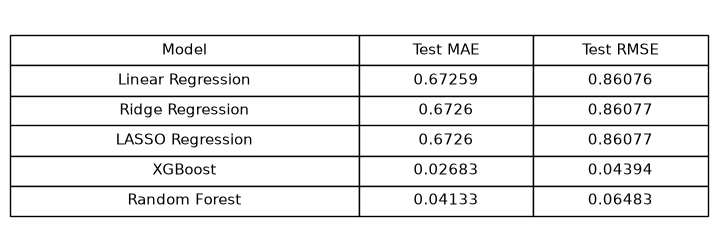

In [36]:
# Compare the performance of all models on the test set

comparison_df = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression", "LASSO Regression", "XGBoost", "Random Forest"],
    "Test MAE": [
        linear_regression_results_test["mae"],
        ridge_results_test["mae"],
        lasso_results_test["mae"],
        xgboost_results_test["mae"],
        random_forest_results_test["mae"]
    ],
    "Test RMSE": [
        linear_regression_results_test["rmse"],
        ridge_results_test["rmse"],
        lasso_results_test["rmse"],
        xgboost_results_test["rmse"],
        random_forest_results_test["rmse"]
    ]
})

display(comparison_df.round(5))

# Create a figure for the table
fig, ax = plt.subplots(figsize=(9, 3))
ax.axis("off")

table = ax.table(
    cellText=comparison_df.round(5).values,
    colLabels=comparison_df.columns,
    colWidths=[0.5, 0.25, 0.25],
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.8)

# Save and display the figure
fig.savefig(
    RESULTS_DIR / "test_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

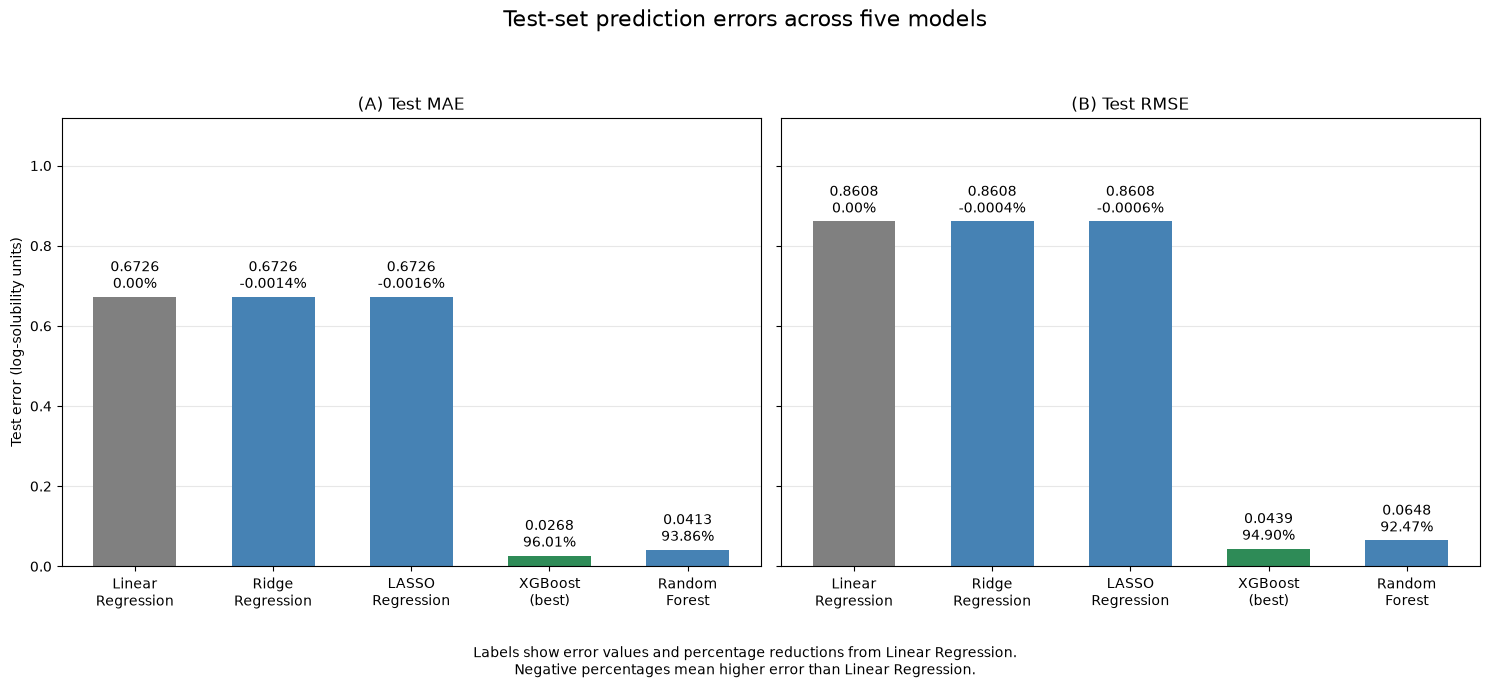

In [37]:
# Model names
models = [
    "Linear\nRegression",
    "Ridge\nRegression",
    "LASSO\nRegression",
    "XGBoost\n(best)",
    "Random\nForest"
]

# Test errors for each model
mae = [
    linear_regression_results_test["mae"],
    ridge_results_test["mae"],
    lasso_results_test["mae"],
    xgboost_results_test["mae"],
    random_forest_results_test["mae"]
]

rmse = [
    linear_regression_results_test["rmse"],
    ridge_results_test["rmse"],
    lasso_results_test["rmse"],
    xgboost_results_test["rmse"],
    random_forest_results_test["rmse"]
]

# Grey = baseline, blue = other models, green = XGBoost
colors = ["grey", "steelblue", "steelblue", "seagreen", "steelblue"]

# Create two graphs
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)

errors = [mae, rmse]
titles = ["(A) Test MAE", "(B) Test RMSE"]

# Use the same vertical scale for both graphs
upper_limit = max(max(mae), max(rmse)) * 1.3

for i in range(2):
    values = errors[i]
    baseline = values[0]

    axes[i].bar(range(5), values, color=colors, width=0.6)

    # Add error values and percentage reductions
    for j in range(5):
        reduction = (baseline - values[j]) / baseline * 100

        # Show extra decimals for very small reductions
        if 0 < abs(reduction) < 0.01:
            percentage = f"{reduction:.4f}%"
        else:
            percentage = f"{reduction:.2f}%"

        label = f"{values[j]:.4f}\n{percentage}"

        axes[i].text(
            j,
            values[j] + upper_limit * 0.02,
            label,
            ha="center",
            fontsize=10
        )

    axes[i].set_title(titles[i])
    axes[i].set_xticks(range(5))
    axes[i].set_xticklabels(models)
    axes[i].set_ylim(0, upper_limit)
    axes[i].set_axisbelow(True)
    axes[i].grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Test error (log-solubility units)")

fig.suptitle("Test-set prediction errors across five models", fontsize=16)

fig.text(
    0.5,
    0.03,
    "Labels show error values and percentage reductions from Linear Regression.\n"
    "Negative percentages mean higher error than Linear Regression.",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.1, 1, 0.93])

# Save the graph
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(RESULTS_DIR / "test_mae_rmse_comparison.png", dpi=300)

plt.show()

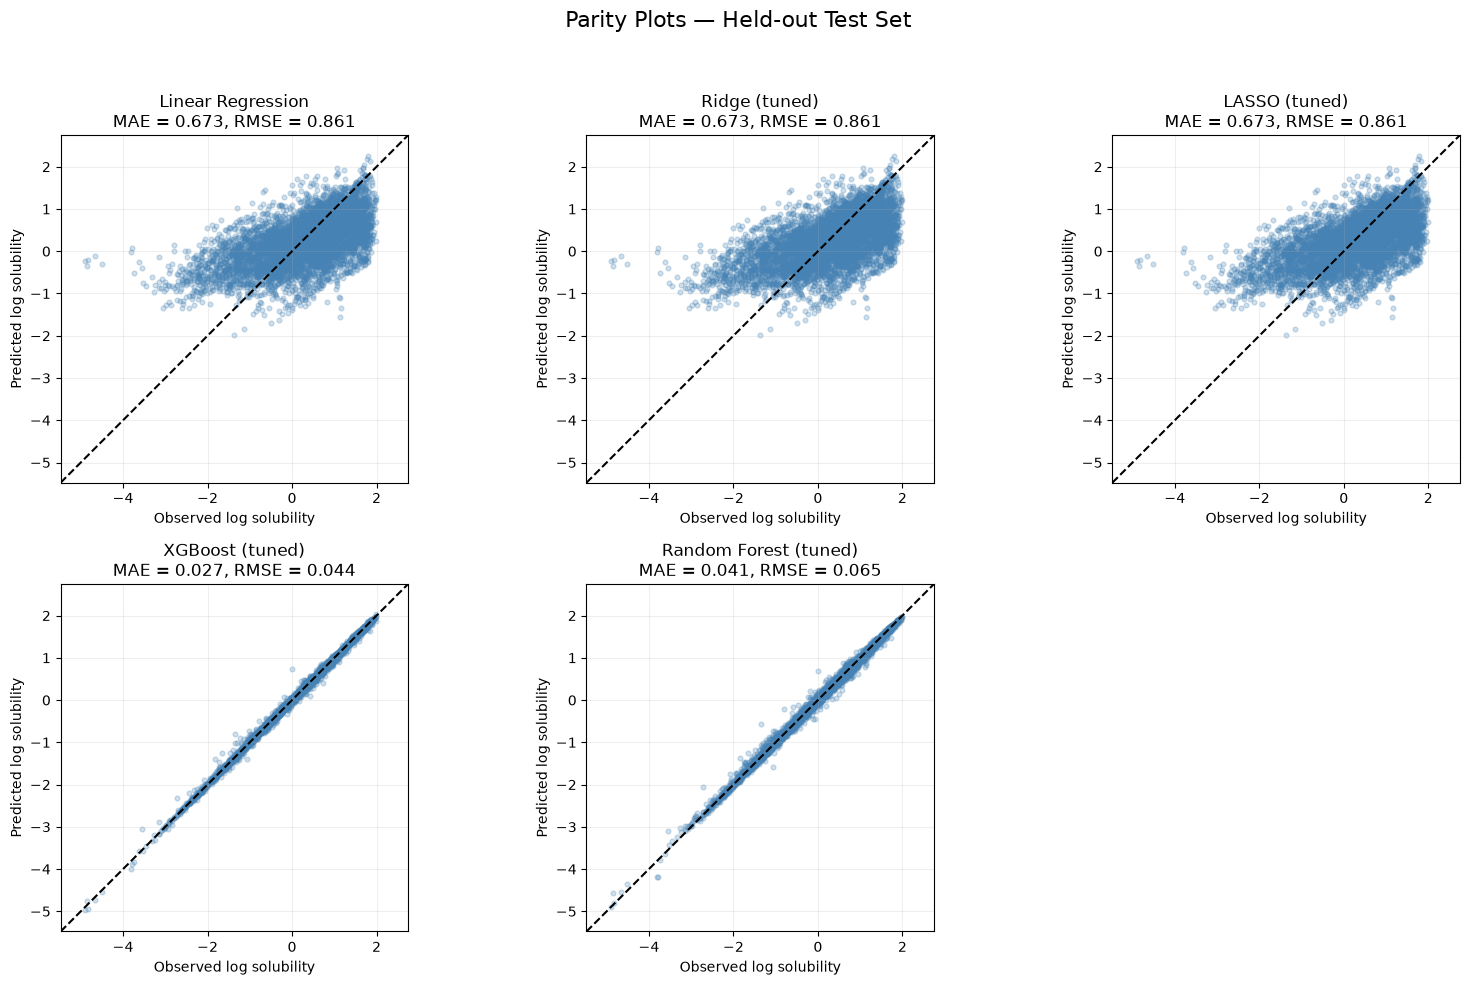

In [38]:
# List the five fitted models
models = [
    LinearRegression_Model,
    ridge_grid.best_estimator_,
    lasso_grid.best_estimator_,
    XGBoost_Tuned_Model,
    RandomForest_Tuned_Model
]

model_names = [
    "Linear Regression",
    "Ridge (tuned)",
    "LASSO (tuned)",
    "XGBoost (tuned)",
    "Random Forest (tuned)"
]

# Observed test values
y_test = test_df[LogSolubility]

# Get test predictions from each model
predictions = []

for model in models:
    y_pred = model.predict(X_test)
    predictions.append(y_pred)

# Find common axis limits for all plots
lower = y_test.min()
upper = y_test.max()

for y_pred in predictions:
    lower = min(lower, y_pred.min())
    upper = max(upper, y_pred.max())

lower = lower - 0.5
upper = upper + 0.5

# Create five parity plots
plt.figure(figsize=(16, 10))

for i in range(5):
    ax = plt.subplot(2, 3, i + 1)

    y_pred = predictions[i]

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    plt.scatter(
        y_test, y_pred,
        color="steelblue", alpha=0.25, s=12
    )

    # Dashed line represents perfect predictions
    plt.plot(
        [lower, upper], [lower, upper],
        color="black", linestyle="--"
    )

    plt.xlim(lower, upper)
    plt.ylim(lower, upper)
    ax.set_aspect("equal", adjustable="box")

    plt.xlabel("Observed log solubility")
    plt.ylabel("Predicted log solubility")
    plt.title(
        model_names[i]
        + "\nMAE = " + str(round(mae, 3))
        + ", RMSE = " + str(round(rmse, 3))
    )
    plt.grid(alpha=0.2)

plt.suptitle("Parity Plots — Held-out Test Set", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])

# Save the graph
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(RESULTS_DIR / "Parity_Plots.png", dpi=300)

plt.show()